# Qubench ⚖️⚛️
### A fair jury needs a fair algorithm
**IBM Qiskit Fall Fest 2026 · UW Quantum Club**
Team: [Team member 1], [Team member 2], [Team member 3]

Qubench is a bridge from a real justice problem (selecting a jury that is random, representative of the community, and checkable) to a quantum algorithm (QAOA) in Qiskit. A court jury administrator can draw a balanced jury and get an audit receipt without knowing anything about quantum computing.

Along the way we found something important: **the standard QAOA plays favourites** among juries that are equally fair, while a **Grover-mixer QAOA** gives every equally fair jury exactly the same chance.


**This notebook is self-contained.** It needs only `qiskit`, `qiskit-aer`, `numpy`, `scipy`, `pandas` and `matplotlib` (plus `qiskit-ibm-runtime` for the noisy-hardware section). It has been run top to bottom, so every result below is already shown.

**Contents**
1. The problem
2. The data (synthetic people)
3. Bridge in: from fairness rules to a quantum operator
4. Two quantum circuits: standard QAOA vs Grover-mixer QAOA
5. Training and checking the circuits
6. Results: is the algorithm fair?
7. The abstraction: `draw_jury()` with an audit receipt
8. Upload your own juror list
9. Real hardware: what noise does
10. Honest limits and next steps

## 1. The problem
Canadian juries are supposed to be **random** (nobody can steer them) and **representative** (they look like the community). In 2018, in the case over the 2016 killing of Colten Boushie, a 22-year-old Cree man, a jury with no Indigenous members acquitted the accused after five visibly Indigenous people were removed during selection. Canada abolished peremptory challenges in 2019.

In Ontario today, the province takes everyone registered with OHIP, randomly mails jury questionnaires, places eligible people on a jury roll, and randomly summons them (Ontario *Juries Act*, R.S.O. 1990, c. J.3). That is random, but nothing targets balance, and the lists are kept secret by law, so the public cannot check a draw.

**Our question:** can we pick a jury that is random *and* balanced *and* checkable, and if a quantum computer does the picking, **is the quantum algorithm itself fair?**

In [1]:
# If needed:  pip install qiskit qiskit-aer qiskit-ibm-runtime numpy scipy pandas matplotlib
import warnings; warnings.filterwarnings("ignore")
import qiskit, qiskit_aer
print("Qiskit", qiskit.__version__, "| Aer", qiskit_aer.__version__)

Qiskit 2.6.1 | Aer 0.18.2


## 2. The data
All people are **fictional**. Each pool is deliberately **skewed** (too many people aged 55+, too many from the North), so we can see whether the algorithm fixes the imbalance. The community targets say what a fair jury should look like.

In [2]:
import io
import pandas as pd

JURORS_8 = """juror_id,name,neighbourhood,age_group,gender
J01,Aria Mockridge,South,35-54,Man
J02,Priya Synthwell,West,55+,Man
J03,Isla Synthwell,North,35-54,Woman
J04,Chloe Testwood,North,55+,Woman
J05,Liam Placeholder,East,18-34,Man
J06,Lucas Sampleton,West,55+,Woman
J07,Noor Notreal,North,55+,Man
J08,Diego Placeholder,South,18-34,Woman"""
JURORS_12 = """juror_id,name,neighbourhood,age_group,gender
J01,Isla Exampleby,South,18-34,Woman
J02,Sofia Demoss,South,55+,Man
J03,Noor Synthwell,North,55+,Man
J04,Hana Demoss,West,55+,Man
J05,Ayasha Synthwell,North,18-34,Man
J06,Lucas Synthwell,East,35-54,Woman
J07,Noor Fauxley,West,55+,Woman
J08,Hana Exampleby,North,18-34,Woman
J09,Ayasha Exampleby,North,55+,Man
J10,Isla Placeholder,West,35-54,Woman
J11,Ethan Exampleby,North,35-54,Man
J12,Diego Testwood,South,55+,Man"""
TARGETS = """attribute,group,community_share
neighbourhood,North,0.25
neighbourhood,South,0.25
neighbourhood,East,0.25
neighbourhood,West,0.25
age_group,18-34,0.3
age_group,35-54,0.35
age_group,55+,0.35
gender,Woman,0.5
gender,Man,0.5"""

jurors8 = pd.read_csv(io.StringIO(JURORS_8))
jurors12 = pd.read_csv(io.StringIO(JURORS_12))
targets = pd.read_csv(io.StringIO(TARGETS))
display(jurors8)
display(targets)

,juror_id,name,neighbourhood,age_group,gender
0,J01,Aria Mockridge,South,35-54,Man
1,J02,Priya Synthwell,West,55+,Man
2,J03,Isla Synthwell,North,35-54,Woman
3,J04,Chloe Testwood,North,55+,Woman
4,J05,Liam Placeholder,East,18-34,Man
5,J06,Lucas Sampleton,West,55+,Woman
6,J07,Noor Notreal,North,55+,Man
7,J08,Diego Placeholder,South,18-34,Woman


,attribute,group,community_share
0,neighbourhood,North,0.25
1,neighbourhood,South,0.25
2,neighbourhood,East,0.25
3,neighbourhood,West,0.25
4,age_group,18-34,0.30
5,age_group,35-54,0.35
6,age_group,55+,0.35
7,gender,Woman,0.50
8,gender,Man,0.50


In [3]:
# How skewed is the 8-person pool compared with the community?
rows = []
for t in targets.itertuples():
    share = (jurors8[t.attribute] == t.group).mean()
    rows.append({"group": t.group, "in pool": f"{share:.0%}", "community": f"{t.community_share:.0%}"})
pd.DataFrame(rows)

,group,in pool,community
0,North,38%,25%
1,South,25%,25%
2,East,12%,25%
3,West,25%,25%
4,18-34,25%,30%
5,35-54,25%,35%
6,55+,50%,35%
7,Woman,50%,50%
8,Man,50%,50%


## 3. Bridge in: from fairness rules to a quantum operator
- **Each juror is one qubit:** measured 1 means selected, 0 means not selected.
- **Cost = how unbalanced a jury is:** for every group (North, 18–34, Woman, …) we take *(jurors picked from the group − target)²* and add them up. Lower is fairer.
- The cost is written as a **QUBO** (only yes/no variables, single terms and pair terms), then converted to a **quantum operator** of Pauli-Z terms using x = (1 − Z)/2.

The next cell holds the problem class; the one after it the QUBO → operator translation.

In [4]:
from __future__ import annotations

import itertools
import math
from dataclasses import dataclass, field

import numpy as np
import pandas as pd
from scipy.optimize import minimize
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import PauliEvolutionGate, RYGate
from qiskit.quantum_info import SparsePauliOp


# ---------------------------------------------------------------------------
from IPython.display import display

In [5]:
# 1. The real-world problem
# ---------------------------------------------------------------------------
@dataclass
class JuryProblem:
    """A pool of jurors, the community's makeup, and how many jurors to pick."""

    jurors: pd.DataFrame          # columns: juror_id, name, + one column per attribute
    targets: pd.DataFrame         # columns: attribute, group, community_share
    k: int                        # jury size
    size_penalty: float = 10.0    # only used by standard QAOA (keeps the jury size right)
    groups: list = field(init=False)

    def __post_init__(self):
        self.jurors = self.jurors.reset_index(drop=True)
        # For every group (e.g. "age_group = 55+"): which jurors are in it, and the target count
        self.groups = []
        for row in self.targets.itertuples():
            members = [i for i, v in enumerate(self.jurors[row.attribute]) if v == row.group]
            self.groups.append((row.attribute, row.group, members, self.k * row.community_share))

    @classmethod
    def from_csv(cls, jurors_csv, targets_csv, k):
        return cls(pd.read_csv(jurors_csv), pd.read_csv(targets_csv), k)

    @property
    def n(self) -> int:
        return len(self.jurors)

    # --- classical cost of a jury (used to check answers) ---------------------------
    def balance_cost(self, selection) -> float:
        """Sum over groups of (jurors picked from group - target)^2.  0 would be perfect."""
        selection = np.asarray(selection)
        return float(sum((selection[m].sum() - t) ** 2 for _, _, m, t in self.groups))

    def all_juries(self):
        """Every possible jury of exactly k people, with its balance cost (small pools only)."""
        out = []
        for combo in itertools.combinations(range(self.n), self.k):
            sel = np.zeros(self.n, dtype=int)
            sel[list(combo)] = 1
            out.append((combo, self.balance_cost(sel)))
        return out

    def optimal_juries(self, tol=1e-9):
        """The juries that tie for the lowest balance cost ("equally fair juries")."""
        juries = self.all_juries()
        best = min(c for _, c in juries)
        return [combo for combo, c in juries if c <= best + tol], best

In [6]:
# ---------------------------------------------------------------------------
# 2. Bridge IN: real problem -> quantum operator (QUBO -> Pauli Z terms)
# ---------------------------------------------------------------------------
def _qubo_terms(problem: JuryProblem, include_size_penalty: bool):
    """Write the cost as  const + sum_i lin[i] x_i + sum_{i<j} quad[i,j] x_i x_j  (x in {0,1})."""
    const, lin, quad = 0.0, np.zeros(problem.n), np.zeros((problem.n, problem.n))

    def add_square(members, target, weight=1.0):
        # weight * (sum_{i in members} x_i - target)^2, using x_i^2 = x_i
        nonlocal const
        const_add = weight * target ** 2
        for i in members:
            lin[i] += weight * (1 - 2 * target)
        for a, b in itertools.combinations(members, 2):
            quad[a, b] += 2 * weight
        const += const_add

    for _, _, members, target in problem.groups:
        add_square(members, target)
    if include_size_penalty:
        add_square(list(range(problem.n)), problem.k, problem.size_penalty)
    return const, lin, quad


def cost_operator(problem: JuryProblem, include_size_penalty: bool) -> SparsePauliOp:
    """Turn the QUBO into a quantum operator using x_i = (1 - Z_i) / 2."""
    const, lin, quad = _qubo_terms(problem, include_size_penalty)
    n = problem.n
    terms = {"": const}

    def add(label_qubits, coeff):
        key = tuple(sorted(label_qubits))
        terms[key] = terms.get(key, 0.0) + coeff

    for i in range(n):                      # lin * (1 - Z_i)/2
        add((), lin[i] / 2)
        add((i,), -lin[i] / 2)
    for i, j in zip(*np.nonzero(quad)):     # quad * (1 - Z_i - Z_j + Z_i Z_j)/4
        q = quad[i, j]
        add((), q / 4)
        add((i,), -q / 4)
        add((j,), -q / 4)
        add((i, j), q / 4)

    sparse = [("Z" * len(k), list(k), v) for k, v in terms.items() if k != "" and abs(v) > 1e-12]
    identity = sum(v for k, v in terms.items() if k in ("", ()))
    sparse.append(("", [], identity))
    return SparsePauliOp.from_sparse_list(sparse, num_qubits=n).simplify()


def dicke_state(n: int, k: int) -> np.ndarray:
    """Equal superposition of every jury with exactly k people (a 'Dicke state') - as a vector."""
    vec = np.zeros(2 ** n, dtype=complex)
    for combo in itertools.combinations(range(n), k):
        vec[sum(1 << q for q in combo)] = 1.0
    return vec / np.linalg.norm(vec)


def _split_and_cyclic_shift(qc: QuantumCircuit, l: int, k: int):
    """One building block of the Bärtschi-Eidenbenz (2019) Dicke-state circuit, on qubits 0..l-1."""
    qc.cx(l - 2, l - 1)
    qc.cry(2 * math.acos(math.sqrt(1 / l)), l - 1, l - 2)
    qc.cx(l - 2, l - 1)
    for i in range(2, k + 1):
        qc.cx(l - 1 - i, l - 1)
        qc.append(RYGate(2 * math.acos(math.sqrt(i / l))).control(2), [l - 1, l - i, l - 1 - i])
        qc.cx(l - 1 - i, l - 1)


def dicke_circuit(n: int, k: int) -> QuantumCircuit:
    """Efficient circuit that prepares the Dicke state (every size-k jury, equally weighted).

    Uses the deterministic construction of Bärtschi & Eidenbenz (2019): O(n*k) gates, far
    shallower than generic state preparation - which matters a lot on real, noisy hardware.
    """
    qc = QuantumCircuit(n, name=f"Dicke({n},{k})")
    qc.x(range(n - k, n))
    for l in range(n, k, -1):
        _split_and_cyclic_shift(qc, l, k)
    for l in range(k, 1, -1):
        _split_and_cyclic_shift(qc, l, l - 1)
    return qc

In [7]:
p8 = JuryProblem(jurors8, targets, k=3)
optimal, best = p8.optimal_juries()
print(f"8 jurors, choose 3: {len(p8.all_juries())} possible juries, {len(optimal)} tie for the fairest (cost {best:.3f})")
op = cost_operator(p8, include_size_penalty=False)
print(f"Quantum cost operator: {op.num_qubits} qubits, {len(op)} Pauli terms")
print(op[:6])

8 jurors, choose 3: 56 possible juries, 5 tie for the fairest (cost 1.265)
Quantum cost operator: 8 qubits, 29 Pauli terms
SparsePauliOp(['IIIIIIII', 'IIIIIIIZ', 'IIIIIIZI', 'IIIIIZII', 'IIIIZIII', 'IIIZIIII'],
              coeffs=[ 6.565+0.j, -0.7  +0.j, -1.7  +0.j, -1.2  +0.j, -2.2  +0.j, -0.35 +0.j])


## 4. Two quantum circuits
**Standard QAOA** starts from every bit-string (any jury size), alternates a *cost* layer and an *X mixer* layer, and uses a penalty to keep the jury size right.

**Grover-mixer QAOA ("fair QAOA")** makes two changes:
1. It starts in a **Dicke state**: an equal superposition of *only* the juries with exactly *k* people. We build it with the efficient Bärtschi–Eidenbenz (2019) circuit.
2. It uses the **Grover mixer** exp(−iβ|D⟩⟨D|), which treats every valid jury symmetrically. Juries with the same cost therefore **always keep exactly the same probability**: fair sampling is guaranteed by the maths.

In [8]:
# ---------------------------------------------------------------------------
# 3. The two quantum circuits (these are what run on IBM hardware)
# ---------------------------------------------------------------------------
def standard_qaoa_circuit(problem: JuryProblem, reps: int) -> QuantumCircuit:
    """Textbook QAOA: start in all possible juries (any size), alternate cost + X-mixer layers."""
    op = cost_operator(problem, include_size_penalty=True)
    gammas, betas = ParameterVector("γ", reps), ParameterVector("β", reps)
    qc = QuantumCircuit(problem.n, name="standard_qaoa")
    qc.h(range(problem.n))
    for layer in range(reps):
        qc.append(PauliEvolutionGate(op, time=gammas[layer]), range(problem.n))   # "cost" step
        qc.rx(2 * betas[layer], range(problem.n))                                 # "mixer" step
    return qc


def fair_qaoa_circuit(problem: JuryProblem, reps: int) -> QuantumCircuit:
    """Grover-Mixer QAOA: start in every jury of size k, alternate cost + Grover-mixer layers.

    Grover mixer = exp(-i β |D><D|), where |D> is the starting (Dicke) state.
    Built as:  S^dagger -> phase on |00..0> -> S,  where S prepares |D>.
    Because this mixer treats all states symmetrically, equally-fair juries ALWAYS keep
    equal probability -> fair sampling is guaranteed by the math.
    """
    n = problem.n
    op = cost_operator(problem, include_size_penalty=False)   # jury size is built in, no penalty
    prep = dicke_circuit(n, problem.k).to_gate(label="Dicke")
    gammas, betas = ParameterVector("γ", reps), ParameterVector("β", reps)

    qc = QuantumCircuit(n, name="fair_qaoa")
    qc.append(prep, range(n))
    for layer in range(reps):
        qc.append(PauliEvolutionGate(op, time=gammas[layer]), range(n))           # "cost" step
        qc.append(prep.inverse(), range(n))                                        # Grover mixer:
        qc.x(range(n))                                                             #   flip to find |0..0>
        qc.mcp(-betas[layer], list(range(n - 1)), n - 1)                           #   phase on it
        qc.x(range(n))
        qc.append(prep, range(n))
    return qc

In [9]:
# The Dicke-state circuit really prepares every 3-person jury of 8 with equal weight
from qiskit.quantum_info import Statevector
fid = abs(np.vdot(dicke_state(8, 3), Statevector(dicke_circuit(8, 3)).data)) ** 2
print(f"Dicke(8,3) fidelity: {fid:.10f}")
print(dicke_circuit(4, 2).draw("text", fold=110))

Dicke(8,3) fidelity: 1.0000000000
                                                                                  ┌───────────┐          »
q_0: ──────────────────────────────────────────────────────────────────────────■──┤ Ry(1.231) ├──■────■──»
                                     ┌─────────┐          ┌────────────┐       │  └─────┬─────┘  │  ┌─┴─┐»
q_1: ─────────────────────────────■──┤ Ry(π/2) ├──■────■──┤ Ry(1.9106) ├──■────┼────────■────────┼──┤ X ├»
     ┌───┐     ┌──────────┐       │  └────┬────┘  │  ┌─┴─┐└─────┬──────┘┌─┴─┐┌─┴─┐      │      ┌─┴─┐└───┘»
q_2: ┤ X ├──■──┤ Ry(2π/3) ├──■────┼───────■───────┼──┤ X ├──────■───────┤ X ├┤ X ├──────■──────┤ X ├─────»
     ├───┤┌─┴─┐└────┬─────┘┌─┴─┐┌─┴─┐     │     ┌─┴─┐└───┘              └───┘└───┘             └───┘     »
q_3: ┤ X ├┤ X ├─────■──────┤ X ├┤ X ├─────■─────┤ X ├────────────────────────────────────────────────────»
     └───┘└───┘            └───┘└───┘           └───┘                                                    »
«  

## 5. Training and checking the circuits
QAOA has angles (γ, β) for each layer. A classical optimiser (COBYLA) tunes them to maximise the chance of measuring one of the fairest juries, using an exact statevector calculation for speed. We then check that the **Qiskit circuits give exactly the same probabilities** as that calculation.

In [10]:
# ---------------------------------------------------------------------------
# 4. Fast exact simulation (used to TRAIN the angles; matches the circuits above)
# ---------------------------------------------------------------------------
class _ExactSimulator:
    """Statevector maths in numpy - same result as the Qiskit circuits, but much faster for training."""

    def __init__(self, problem: JuryProblem, method: str):
        self.n, self.method = problem.n, method
        idx = np.arange(2 ** self.n)
        bits = (idx[:, None] >> np.arange(self.n)) & 1            # bits[state, qubit]
        self.selections = bits
        self.balance = np.array([problem.balance_cost(b) for b in bits])
        size_pen = problem.size_penalty * (bits.sum(1) - problem.k) ** 2
        self.diag = self.balance + (size_pen if method == "standard" else 0.0)
        if method == "standard":
            self.start = np.full(2 ** self.n, 1 / math.sqrt(2 ** self.n), dtype=complex)
        else:
            self.start = dicke_state(self.n, problem.k)

    def state(self, gammas, betas):
        psi = self.start.copy()
        for g, b in zip(gammas, betas):
            psi = psi * np.exp(-1j * g * self.diag)
            if self.method == "standard":
                rx = np.array([[math.cos(b), -1j * math.sin(b)], [-1j * math.sin(b), math.cos(b)]])
                t = psi.reshape([2] * self.n)
                for ax in range(self.n):
                    t = np.moveaxis(np.tensordot(rx, t, axes=([1], [ax])), 0, ax)
                psi = t.reshape(-1)
            else:
                overlap = np.vdot(self.start, psi)
                psi = psi + (np.exp(-1j * b) - 1) * overlap * self.start
        return psi

    def probabilities(self, gammas, betas):
        return np.abs(self.state(gammas, betas)) ** 2


def train_angles(problem: JuryProblem, method: str, reps: int = 3, restarts: int = 8, seed: int = 0):
    """Find the γ, β angles that make low-cost (fair) juries most likely.

    Objective: maximise the probability of landing on one of the equally-fair (optimal) juries.
    Classical optimiser (COBYLA) + quantum circuit = a 'variational' quantum algorithm.
    """
    sim = _ExactSimulator(problem, method)
    best_cost = sim.balance[sim.selections.sum(1) == problem.k].min()
    is_opt = (np.abs(sim.balance - best_cost) < 1e-9) & (sim.selections.sum(1) == problem.k)

    rng = np.random.default_rng(seed)
    best = None
    for _ in range(restarts):
        x0 = np.concatenate([rng.uniform(0, 1.0, reps), rng.uniform(0, math.pi, reps)])
        obj = lambda x: -sim.probabilities(x[:reps], x[reps:])[is_opt].sum()
        res = minimize(obj, x0, method="COBYLA", options={"maxiter": 400})
        if best is None or res.fun < best.fun:
            best = res
    gammas, betas = best.x[:reps], best.x[reps:]
    return {"method": method, "reps": reps, "gammas": gammas.tolist(), "betas": betas.tolist(),
            "p_optimal": float(-best.fun)}


def bind(circuit: QuantumCircuit, angles: dict) -> QuantumCircuit:
    """Plug trained angles into a circuit."""
    values = {}
    for p in circuit.parameters:
        vec = angles["gammas"] if p.name.startswith("γ") else angles["betas"]
        values[p] = vec[p.index]
    return circuit.assign_parameters(values)


def build_circuit(problem: JuryProblem, angles: dict) -> QuantumCircuit:
    maker = standard_qaoa_circuit if angles["method"] == "standard" else fair_qaoa_circuit
    return bind(maker(problem, angles["reps"]), angles)

In [11]:
# ---------------------------------------------------------------------------
# 5. Bridge OUT: measured bitstrings -> juries, plus fairness metrics
# ---------------------------------------------------------------------------
def bits_to_selection(bitstring: str) -> tuple:
    """Qiskit bitstring (qubit 0 on the right) -> tuple of selected juror indices."""
    return tuple(i for i, b in enumerate(reversed(bitstring)) if b == "1")


def fairness_report(problem: JuryProblem, counts: dict) -> dict:
    """How often each equally-fair jury was drawn, and how fair that spread is.

    fairness_score = normalised Shannon entropy over the equally-fair juries
                     1.0 = perfectly even (fair), 0.0 = always the same jury.
    """
    optimal, best_cost = problem.optimal_juries()
    opt_set = set(optimal)
    tally = {j: 0 for j in optimal}
    total = valid = 0
    for bits, c in counts.items():
        sel = bits_to_selection(bits)
        total += c
        if sel in opt_set:
            tally[sel] += c
            valid += c
    freqs = np.array([tally[j] for j in optimal], dtype=float)
    share = freqs / freqs.sum() if freqs.sum() else freqs
    nz = share[share > 0]
    entropy = float(-(nz * np.log(nz)).sum())
    score = entropy / math.log(len(optimal)) if len(optimal) > 1 else 1.0
    person_rate = np.zeros(problem.n)
    for j, c in tally.items():
        person_rate[list(j)] += c
    person_rate = person_rate / valid if valid else person_rate
    return {
        "optimal_juries": optimal,
        "best_cost": best_cost,
        "counts_per_optimal_jury": dict(zip(optimal, freqs.astype(int).tolist())),
        "share_per_optimal_jury": dict(zip(optimal, share.tolist())),
        "prob_optimal": valid / total if total else 0.0,
        "fairness_score": score,
        "max_over_min": float(freqs.max() / freqs.min()) if freqs.min() > 0 else float("inf"),
        "person_selection_rate": person_rate.tolist(),
    }

In [12]:
%%time
p12 = JuryProblem(jurors12, targets, k=4)
ANGLES = {}
for name, prob in (("n8", p8), ("n12", p12)):
    for method in ("standard", "fair"):
        ANGLES[(name, method)] = train_angles(prob, method, reps=3)
        print(f"{name} {method:8s} P(lands on a fairest jury) = {ANGLES[(name, method)]['p_optimal']:.1%}")

n8 standard P(lands on a fairest jury) = 20.6%


n8 fair     P(lands on a fairest jury) = 82.4%


n12 standard P(lands on a fairest jury) = 4.4%


n12 fair     P(lands on a fairest jury) = 14.6%
CPU times: user 18.1 s, sys: 12.3 ms, total: 18.1 s
Wall time: 18.2 s


In [13]:
# Check: Qiskit circuits == exact calculation
for method in ("standard", "fair"):
    ang = ANGLES[("n8", method)]
    circuit_probs = Statevector(build_circuit(p8, ang)).probabilities()
    exact_probs = _ExactSimulator(p8, method).probabilities(ang["gammas"], ang["betas"])
    print(f"{method:8s} max difference: {np.abs(circuit_probs - exact_probs).max():.1e}")

standard max difference: 3.2e-16


fair     max difference: 2.2e-16


## 6. Results: is the algorithm fair?
We run each trained circuit **20,000 times on the Qiskit Aer simulator** and count how often each of the equally fair juries comes out. A fair algorithm picks them all equally often.

**Favouritism** = most-picked fair jury ÷ least-picked fair jury (1.00× is perfectly fair).

In [14]:
from qiskit import transpile
from qiskit_aer import AerSimulator
backend = AerSimulator()

def sample(problem, angles, shots=20000, seed=11):
    qc = build_circuit(problem, angles); qc.measure_all()
    return backend.run(transpile(qc, backend), shots=shots, seed_simulator=seed).result().get_counts()

REPORTS = {}
rows = []
for name, prob in (("n8", p8), ("n12", p12)):
    for method in ("standard", "fair"):
        rep = fairness_report(prob, sample(prob, ANGLES[(name, method)]))
        REPORTS[(name, method)] = rep
        rows.append({"pool": f"{prob.n} choose {prob.k}", "method": method, "equally fair juries": len(rep["optimal_juries"]),
                     "lands on a fairest jury": f"{rep['prob_optimal']:.0%}", "favouritism": f"{rep['max_over_min']:.2f}x",
                     "fairness score": round(rep["fairness_score"], 3)})
pd.DataFrame(rows)

,pool,method,equally fair juries,lands on a fairest jury,favouritism,fairness score
0,8 choose 3,standard,5,20%,1.32x,0.997
1,8 choose 3,fair,5,82%,1.04x,1.000
2,12 choose 4,standard,9,4%,3.00x,0.972
3,12 choose 4,fair,9,15%,1.17x,0.999


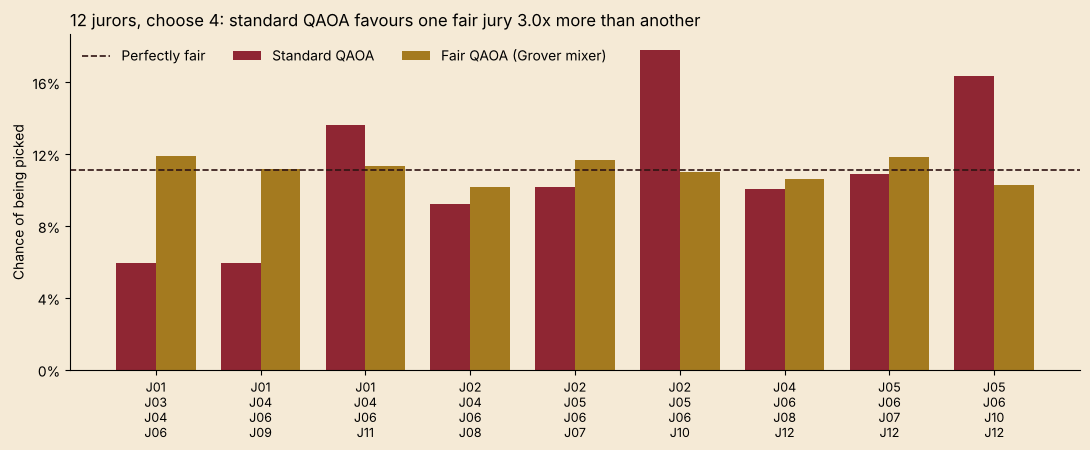

In [15]:
import matplotlib.pyplot as plt
C_STD, C_FAIR, INK, SURF = "#8f2633", "#a47a1f", "#301413", "#f5ead6"
rep_s, rep_f = REPORTS[("n12", "standard")], REPORTS[("n12", "fair")]
juries = rep_s["optimal_juries"]
x = np.arange(len(juries)); w = 0.38
fig, ax = plt.subplots(figsize=(11, 4.6), facecolor=SURF); ax.set_facecolor(SURF)
ax.bar(x - w/2, [rep_s["share_per_optimal_jury"][j] for j in juries], w, color=C_STD, label="Standard QAOA")
ax.bar(x + w/2, [rep_f["share_per_optimal_jury"][j] for j in juries], w, color=C_FAIR, label="Fair QAOA (Grover mixer)")
ax.axhline(1/len(juries), color=INK, ls="--", lw=1.2, label="Perfectly fair")
ax.set_xticks(x, ["\n".join(p12.jurors.loc[list(j), "juror_id"]) for j in juries], fontsize=9)
ax.yaxis.set_major_locator(plt.matplotlib.ticker.MultipleLocator(0.04)); ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=0))
ax.set_ylabel("Chance of being picked"); ax.spines[["top", "right"]].set_visible(False)
ax.set_title(f"12 jurors, choose 4: standard QAOA favours one fair jury {rep_s['max_over_min']:.1f}x more than another", loc="left")
ax.legend(frameon=False, ncol=3, loc="upper left"); plt.tight_layout(); plt.show()

**What this shows:** among the 9 equally balanced juries, standard QAOA picks some about 3× more often than others. Nobody programmed that bias; it comes from how the X mixer moves probability. The Grover-mixer version is flat (up to sampling noise) **and** lands on a fairest jury far more often.

## 7. The abstraction: `draw_jury()`
This is what a non-expert uses. They pass a juror table and a jury size; everything quantum is hidden. Each draw keeps the fairest measured juries and picks **one measured shot at random**, so the algorithm's own odds (fair or biased) are preserved, and returns an **audit receipt**.

In [16]:
import hashlib, json
from datetime import datetime, timezone

def draw_jury(jurors: pd.DataFrame, k: int, method: str = "fair", shots: int = 4000, reps: int = 3, angles=None):
    """Draw one jury with a quantum circuit and return (jury, receipt)."""
    problem = JuryProblem(jurors, targets, k)
    angles = angles or train_angles(problem, method, reps=reps)
    seed = int(np.random.default_rng().integers(2**31))
    counts = sample(problem, angles, shots=shots, seed=seed)
    sized = {b: c for b, c in counts.items() if len(bits_to_selection(b)) == k}
    cost = {b: problem.balance_cost(np.isin(np.arange(problem.n), bits_to_selection(b)).astype(int)) for b in sized}
    best = min(cost.values()); finalists = [b for b in sized if cost[b] <= best + 1e-9]
    weights = np.array([sized[b] for b in finalists], float)
    chosen = bits_to_selection(finalists[np.random.default_rng(seed).choice(len(finalists), p=weights / weights.sum())])
    jury = problem.jurors.iloc[list(chosen)]
    receipt = {"method": method, "backend": "Qiskit Aer simulator", "pool_size": problem.n, "jury_size": k,
               "selected_ids": jury["juror_id"].tolist(), "balance_cost": round(best, 4),
               "best_possible_cost": round(problem.optimal_juries()[1], 4), "shots": shots, "simulator_seed": seed,
               "qaoa_angles": {"gammas": [round(v, 4) for v in angles["gammas"]], "betas": [round(v, 4) for v in angles["betas"]]},
               "counts_sha256": hashlib.sha256(json.dumps(counts, sort_keys=True).encode()).hexdigest(),
               "timestamp_utc": datetime.now(timezone.utc).isoformat(timespec="seconds")}
    return jury, receipt

jury, receipt = draw_jury(jurors8, k=3, method="fair", angles=ANGLES[("n8", "fair")])
display(jury)
print(json.dumps(receipt, indent=2))

,juror_id,name,neighbourhood,age_group,gender
0,J01,Aria Mockridge,South,35-54,Man
3,J04,Chloe Testwood,North,55+,Woman
4,J05,Liam Placeholder,East,18-34,Man


{
  "method": "fair",
  "backend": "Qiskit Aer simulator",
  "pool_size": 8,
  "jury_size": 3,
  "selected_ids": [
    "J01",
    "J04",
    "J05"
  ],
  "balance_cost": 1.265,
  "best_possible_cost": 1.265,
  "shots": 4000,
  "simulator_seed": 970468306,
  "qaoa_angles": {
    "gammas": [
      -0.3972,
      -0.5666,
      -0.6602
    ],
    "betas": [
      1.9659,
      1.7361,
      1.9057
    ]
  },
  "counts_sha256": "f6bb2c2d0086cb9a696e91411fc83660158a23750e6628669ae96a6ba1e6fc1b",
  "timestamp_utc": "2026-11-05T22:19:23+00:00"
}


## 8. Upload your own juror list
Any court office can use its own list (3 to 12 people, since each juror is one qubit). On the website this is a CSV or Excel upload; here we build a table directly. The circuit is trained for the new list, then drawn.

In [17]:
my_list = pd.DataFrame([
    ["A1", "Maya Testperson", "North", "18-34", "Woman"], ["A2", "Ben Example", "North", "55+", "Man"],
    ["A3", "Zara Sample", "South", "35-54", "Woman"],     ["A4", "Leo Mockname", "East", "55+", "Man"],
    ["A5", "Ivy Placeholder", "West", "18-34", "Woman"],  ["A6", "Sam Fakerson", "North", "55+", "Man"],
    ["A7", "Nina Demo", "East", "35-54", "Woman"],        ["A8", "Raj Notreal", "South", "55+", "Man"],
    ["A9", "Tess Synth", "West", "55+", "Woman"],         ["A10", "Omar Instance", "North", "18-34", "Man"],
], columns=["juror_id", "name", "neighbourhood", "age_group", "gender"])
jury, receipt = draw_jury(my_list, k=4, method="fair")
display(jury)
print("balance cost", receipt["balance_cost"], "| best possible", receipt["best_possible_cost"])

,juror_id,name,neighbourhood,age_group,gender
4,A5,Ivy Placeholder,West,18-34,Woman
5,A6,Sam Fakerson,North,55+,Man
6,A7,Nina Demo,East,35-54,Woman
7,A8,Raj Notreal,South,55+,Man


balance cost 0.56 | best possible 0.56


## 9. Real hardware: what noise does
The fair circuit is much deeper than the standard one. We compile both for a real IBM chip layout and run them on **a noisy simulation of the IBM Sherbrooke chip** (`FakeSherbrooke`), using the 6-person pool and one QAOA layer to keep circuits short.

To run on a **real IBM quantum computer**, set up an IBM Quantum account and run `python experiments/run_hardware.py` from the repository (it uses error mitigation: dynamical decoupling and Pauli twirling).

In [18]:
JURORS_6 = """juror_id,name,neighbourhood,age_group,gender
J01,Hana Mockridge,North,55+,Man
J02,Omar Demoss,South,35-54,Woman
J03,Isla Fauxley,East,18-34,Man
J04,Ravi Notreal,North,55+,Woman
J05,Mei Exampleby,West,55+,Woman
J06,Diego Testwood,North,35-54,Man"""
p6 = JuryProblem(pd.read_csv(io.StringIO(JURORS_6)), targets, k=2)
try:
    from qiskit_ibm_runtime.fake_provider import FakeSherbrooke
    noisy = AerSimulator.from_backend(FakeSherbrooke())
    rows = []
    for method in ("standard", "fair"):
        ang = train_angles(p6, method, reps=1)
        qc = build_circuit(p6, ang); qc.measure_all()
        tqc = transpile(qc, noisy, optimization_level=3, seed_transpiler=7)
        twoq = sum(v for g, v in tqc.count_ops().items() if g in ("ecr", "cx", "cz"))
        ideal = fairness_report(p6, sample(p6, ang))
        hw = fairness_report(p6, noisy.run(tqc, shots=4000, seed_simulator=7).result().get_counts())
        rows.append({"method": method, "two-qubit gates": twoq, "depth": tqc.depth(),
                     "ideal: favouritism": f"{ideal['max_over_min']:.2f}x", "noisy chip: favouritism": f"{hw['max_over_min']:.2f}x",
                     "ideal: lands on fairest": f"{ideal['prob_optimal']:.0%}", "noisy chip: lands on fairest": f"{hw['prob_optimal']:.0%}"})
    display(pd.DataFrame(rows))
except ImportError:
    print("Install qiskit-ibm-runtime to run the noisy-chip simulation.")

,method,two-qubit gates,depth,ideal: favouritism,noisy chip: favouritism,ideal: lands on fairest,noisy chip: lands on fairest
0,standard,46,197,1.22x,1.51x,13%,10%
1,fair,390,1720,1.00x,1.01x,33%,5%


**Honest finding:** the fair circuit needs about 8× more two-qubit gates (390 vs 46 here). In a perfect simulation it lands on a fairest jury far more often than the standard circuit; on the noisy chip that drops to about 5%, below the standard circuit, so its advantage is gone. The algorithm is provably fair; today's hardware cannot yet run it faithfully. Qubench measures exactly that gap.

## 10. Honest limits and next steps
**Limits**
- **Small pools only.** Each juror is one qubit, so we stop at 12; a classical computer solves these sizes easily. Our contribution is the bridge and the fairness analysis.
- **Fair juries ≠ equal odds per person.** People who appear in more of the balanced juries are picked more often.
- **Hardware isn't ready.** Noise erases the fair circuit's advantage today.
- **Synthetic people.** We balance neighbourhood, age group and gender, not race directly, and target the pool stage.

**Next steps:** equal odds for every individual; larger pools as hardware improves; error mitigation tuned for the Grover-mixer circuit; certified quantum randomness on real IBM machines.

**References**
- Bärtschi & Eidenbenz (2019), *Deterministic Preparation of Dicke States*; (2020), *Grover Mixers for QAOA*.
- Pelofske et al. (2021), fair sampling with Grover-mixer QAOA on IBM Q backends (arXiv:2101.03258).
- Pelofske (2024), *Biased Degenerate Ground-State Sampling of Small Ising Models with Converged QAOA* (arXiv:2411.05294).
- Flanigan et al. (2021), *Fair algorithms for selecting citizens' assemblies*, Nature 596.
- Ontario *Juries Act*, R.S.O. 1990, c. J.3.